# ANN Mini-Project: Bank Customer Churn Prediction

This notebook follows **Steps 0–8** of `ANN Mini-Project Manual: Customer Churn Predictor App`. Step 9 is provided separately as `app.py`.

**Dataset:** `Churn_Modelling.csv`  
**Target:** `Exited` (1 = customer left, 0 = customer stayed)



## Step 0 — Setup

Install the libraries if they are not already installed. If you are using Google Colab, TensorFlow is usually pre-installed.

In [1]:
%pip install -q tensorflow pandas numpy scikit-learn joblib streamlit matplotlib


In [2]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## Step 1 — Load the data

In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Make results more repeatable
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Load CSV
df = pd.read_csv("Churn_Modelling.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Step 2 — Explore and clean the data

Check data types, missing values and the target distribution. Then remove the three identifier columns listed in the manual.

In [4]:
# Overview of columns and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
# Count missing values in each column
print(df.isnull().sum())


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [6]:
# Count customers who stayed (0) and left (1)
print(df["Exited"].value_counts().sort_index())
print("\nTarget percentages:")
print((df["Exited"].value_counts(normalize=True) * 100).sort_index().round(2))


Exited
0    7963
1    2037
Name: count, dtype: int64

Target percentages:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [7]:
# Drop columns that are identifiers, not useful predictive features
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

print("Shape after dropping ID columns:", df.shape)
display(df.head())


Shape after dropping ID columns: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Step 3 — Split into X, y, training and testing data

`X` contains the input features. `y` contains the answer (`Exited`). Stratification preserves the class ratio in both sets.

In [8]:
X = df.drop(columns=["Exited"])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

print("\nChurn ratio in full data:", round(y.mean(), 3))
print("Churn ratio in training:", round(y_train.mean(), 3))
print("Churn ratio in testing: ", round(y_test.mean(), 3))


X_train: (8000, 10)
X_test:  (2000, 10)
y_train: (8000,)
y_test:  (2000,)

Churn ratio in full data: 0.204
Churn ratio in training: 0.204
Churn ratio in testing:  0.204


## Step 4 — Preprocess: encode text and scale numbers

The manual specifies 8 numeric features, 3 Geography one-hot columns and 2 Gender one-hot columns, giving **13 processed features**. Fit the preprocessor on training data only.

In [9]:
# Separate numeric and categorical feature names
numeric_features = [
    "CreditScore", "Age", "Tenure", "Balance",
    "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"
]
categorical_features = ["Geography", "Gender"]

# OneHotEncoder compatibility with different scikit-learn versions
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", one_hot, categorical_features)
    ]
)

# Fit ONLY on training data; apply the learned transformations to test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape: ", X_test_processed.shape)


Processed training shape: (8000, 13)
Processed testing shape:  (2000, 13)


In [10]:
# Check the number and names of transformed features
feature_names = preprocessor.get_feature_names_out()
print("Number of processed features:", len(feature_names))
print(feature_names)


Number of processed features: 13
['numeric__CreditScore' 'numeric__Age' 'numeric__Tenure'
 'numeric__Balance' 'numeric__NumOfProducts' 'numeric__HasCrCard'
 'numeric__IsActiveMember' 'numeric__EstimatedSalary'
 'categorical__Geography_France' 'categorical__Geography_Germany'
 'categorical__Geography_Spain' 'categorical__Gender_Female'
 'categorical__Gender_Male']


## Step 5 — Build the Artificial Neural Network (ANN)

Use the exact architecture from the manual: 13 inputs → Dense(16, ReLU) → Dense(8, ReLU) → Dense(1, Sigmoid).

In [11]:
model = keras.Sequential([
    keras.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6 — Train the model

Train for up to 50 epochs with batch size 32 and validation split 0.2. EarlyStopping stops training when validation loss does not improve for 5 epochs and restores the best weights.

In [12]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.7633 - loss: 0.5249 - val_accuracy: 0.8000 - val_loss: 0.4610
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7956 - loss: 0.4472 - val_accuracy: 0.8050 - val_loss: 0.4365
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8078 - loss: 0.4233 - val_accuracy: 0.8275 - val_loss: 0.4149
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8255 - loss: 0.4019 - val_accuracy: 0.8444 - val_loss: 0.3901
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8395 - loss: 0.3826 - val_accuracy: 0.8531 - val_loss: 0.3699
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8467 - loss: 0.3689 - val_accuracy: 0.8537 - val_loss: 0.3573
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8481 - loss: 0.3606 - val_accuracy: 0.8575 - val_loss: 0.3504
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8517 - loss: 0.3557 - val_accuracy: 

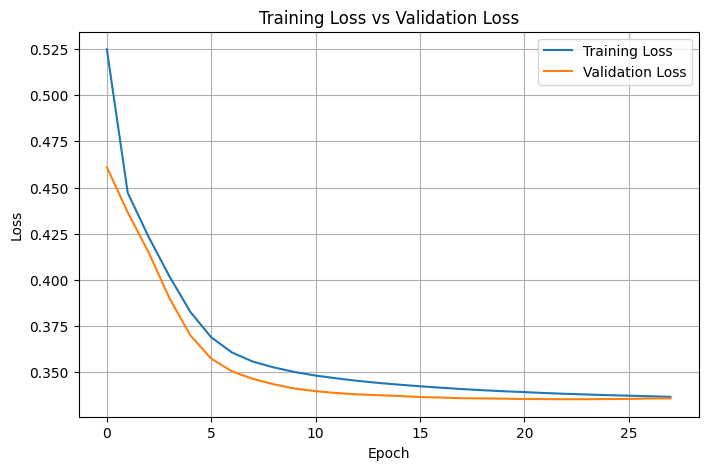

In [13]:
# Plot training loss and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


## Step 7 — Evaluate on the test set

Predict probabilities, convert probabilities to class labels using the manual's 0.5 threshold, and print the required evaluation metrics.

In [14]:
# Predicted probabilities between 0 and 1
y_probability = model.predict(X_test_processed).ravel()

# Convert probabilities into 0/1 predictions
y_pred = (y_probability >= 0.5).astype(int)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Stayed (0)", "Left (1)"]))


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Test Accuracy: 0.8615

Confusion Matrix:
[[1522   71]
 [ 206  201]]

Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.88      0.96      0.92      1593
    Left (1)       0.74      0.49      0.59       407

    accuracy                           0.86      2000
   macro avg       0.81      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



## Step 8 — Save the model and preprocessor

Save both objects. The app needs the preprocessor because new customer inputs must be encoded and scaled exactly like the training data.

In [15]:
import joblib

model.save("model.keras")
joblib.dump(preprocessor, "preprocessor.pkl")

print("Saved model.keras and preprocessor.pkl")


Saved model.keras and preprocessor.pkl


In [16]:
# Sanity check: predict one customer from the test set
sample_customer = X_test.iloc[[0]]
actual_answer = int(y_test.iloc[0])

sample_processed = preprocessor.transform(sample_customer)
sample_probability = float(model.predict(sample_processed, verbose=0)[0][0])
sample_prediction = int(sample_probability >= 0.5)

print("Actual Exited value:", actual_answer)
print("Predicted churn probability:", round(sample_probability * 100, 2), "%")
print("Predicted Exited value:", sample_prediction)
print("Prediction:", "LEAVE" if sample_prediction == 1 else "STAY")


Actual Exited value: 0
Predicted churn probability: 2.77 %
Predicted Exited value: 0
Prediction: STAY
